# 2.08 · Bayesian linear inversion and the MAP

2.07 ended with a problem least squares cannot solve on its own: more slip patterns than the data can see. The
Bayesian answer adds what we know before the data, a prior, and returns a whole distribution of slip models instead
of one. For a linear forward model with Gaussian prior and noise this distribution is Gaussian, has a closed form,
and its peak (the MAP, maximum a posteriori) is exactly a *regularised* least-squares solution: least squares plus a
penalty that discourages implausible models (2.09). This notebook builds that result from one
unknown up to the 30-patch fault.

**Words this notebook defines:** prior, precision, posterior, precision-weighted average, MAP (maximum a
posteriori), objective function, model-space and data-space forms, Kalman gain, posterior covariance, mode, median,
mean, loss function, Laplace approximation, information gain per parameter.

**Before this:** [2.04](2-04_conditional_probability.ipynb), [2.07](2-07_least_squares.ipynb) (and [2.06](2-06_matrix_primer.ipynb) for the matrix steps). · **You will be able to:** combine a Gaussian prior and
a linear forward model into the closed-form posterior; write the MAP as regularised least squares; choose between the
model-space and data-space forms; say which summary (mean, median, MAP) answers which question; judge when a Laplace
approximation is safe. · **Optional sections:** the timing comparison in section 4.

**Problems in this notebook**

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| one slip value, one measurement (section 1) | 1 | 1 | $d = m$ | linear |
| two patches, one or two data (sections 2-3) | 2 | 2 or 1 | $\mathbf d = \mathbf G\mathbf m$ | linear |
| cost of the two forms (section 4) | 50 or 2000 | 2000 or 50 | random $\mathbf G$ | linear |
| positive slip (section 5) | 1 | 1 | $d = s$, prior on $s \ge 0$ | linear, bounded |
| banana (section 6) | 2 | 1 | distance to one station | nonlinear |
| antiplane fault (section 7, as in notebook 2.33) | 30 slip patches | 24 stations | $\mathbf d = \mathbf G\mathbf m$ | linear |

In [1]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as st
from scipy.optimize import minimize
from scipy.special import kv, gamma
import jax, jax.numpy as jnp
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S

np.set_printoptions(precision=4, suppress=True)
C_PRIOR, C_LIK, C_POST = S.MUTED, S.ORANGE, S.INK

## 1. One unknown, one measurement, worked by hand

**In plain words.** Before measuring you think the slip on a patch is about 1 m, give or take 1 m. A measurement
says 2.4 m, give or take 0.6 m. The combined answer lies between the two, closer to the more certain one, and it is
more certain than either. Certainty adds up: each source contributes its **precision**, one over its variance, and
the precisions simply add.

**Precisely.** Prior $m \sim N(m_0, \sigma_m^2)$, datum $d = m + e$ with $e \sim N(0, \sigma_d^2)$. The posterior is
Gaussian with

$$\frac{1}{\tilde\sigma^2} = \frac{1}{\sigma_m^2} + \frac{1}{\sigma_d^2}, \qquad
\bar m = \tilde\sigma^2\left(\frac{m_0}{\sigma_m^2} + \frac{d}{\sigma_d^2}\right)
= w\,m_0 + (1 - w)\,d, \quad w = \frac{\tilde\sigma^2}{\sigma_m^2}.$$

**Worked example** (inputs: $m_0$ = 1 m, $\sigma_m$ = 1 m, $d$ = 2.4 m, $\sigma_d$ = 0.6 m):

In [2]:
m0_1, sm_1, d_1, sd_1 = 1.0, 1.0, 2.4, 0.6
prec_prior, prec_data = 1 / sm_1 ** 2, 1 / sd_1 ** 2
prec_post = prec_prior + prec_data
sig_post = 1 / np.sqrt(prec_post)
w_prior = prec_prior / prec_post
mean_post = w_prior * m0_1 + (1 - w_prior) * d_1
print(f"step 1  precisions: prior 1/{sm_1}^2 = {prec_prior:.3f},  data 1/{sd_1}^2 = {prec_data:.3f}   (units 1/m^2)")
print(f"step 2  posterior precision = {prec_prior:.3f} + {prec_data:.3f} = {prec_post:.3f}  ->  posterior sd = {sig_post:.3f} m")
print(f"step 3  weights: prior {w_prior:.3f}, data {1 - w_prior:.3f}")
print(f"step 4  posterior mean = {w_prior:.3f} x {m0_1} + {1 - w_prior:.3f} x {d_1} = {mean_post:.3f} m")
mm = np.linspace(-2, 5, 2001)
dens = st.norm.pdf(mm, m0_1, sm_1) * st.norm.pdf(d_1, mm, sd_1)
dens /= np.trapezoid(dens, mm)
print(f"check   brute force on a grid: mean {np.trapezoid(mm * dens, mm):.3f} m, sd {np.sqrt(np.trapezoid((mm - mean_post) ** 2 * dens, mm)):.3f} m")

step 1  precisions: prior 1/1.0^2 = 1.000,  data 1/0.6^2 = 2.778   (units 1/m^2)
step 2  posterior precision = 1.000 + 2.778 = 3.778  ->  posterior sd = 0.514 m
step 3  weights: prior 0.265, data 0.735
step 4  posterior mean = 0.265 x 1.0 + 0.735 x 2.4 = 2.029 m
check   brute force on a grid: mean 2.029 m, sd 0.514 m


saved figures/2-08_one_unknown.png


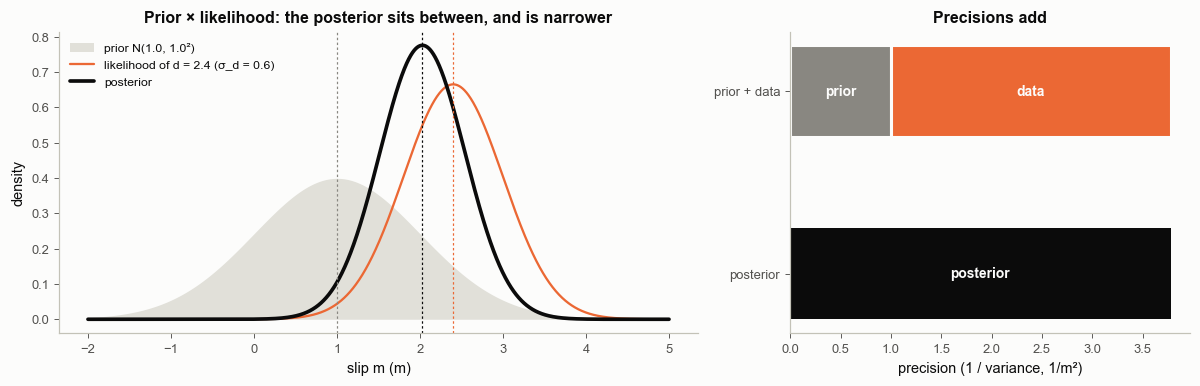

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax = axs[0]
ax.fill_between(mm, st.norm.pdf(mm, m0_1, sm_1), color="#e1e0d9", lw=0, label=f"prior N({m0_1}, {sm_1}²)")
ax.plot(mm, st.norm.pdf(mm, d_1, sd_1), color=C_LIK, lw=1.5, label=f"likelihood of d = {d_1} (σ_d = {sd_1})")
ax.plot(mm, st.norm.pdf(mm, mean_post, sig_post), color=C_POST, lw=2.4, label="posterior")
for x, c in [(m0_1, C_PRIOR), (d_1, C_LIK), (mean_post, C_POST)]:
    ax.axvline(x, color=c, lw=0.8, ls=(0, (2, 2)))
ax.set_xlabel("slip m (m)"); ax.set_ylabel("density")
ax.set_title("Prior × likelihood: the posterior sits between, and is narrower")
ax.legend(fontsize=8, loc="upper left")
ax = axs[1]
bars = [("prior", prec_prior, C_PRIOR), ("data", prec_data, C_LIK)]
left = 0
for name, val, c in bars:
    ax.barh(1, val, left=left, color=c, height=0.5, edgecolor=S.SURFACE, lw=2)
    ax.text(left + val / 2, 1, name, ha="center", va="center", color=S.SURFACE, fontsize=9, fontweight="bold")
    left += val
ax.barh(0, prec_post, color=C_POST, height=0.5)
ax.text(prec_post / 2, 0, "posterior", ha="center", va="center", color=S.SURFACE, fontsize=9, fontweight="bold")
ax.set_yticks([0, 1]); ax.set_yticklabels(["posterior", "prior + data"])
ax.set_xlabel("precision (1 / variance, 1/m²)")
ax.set_title("Precisions add")
fig.tight_layout()
bk.savefig(fig, "2-08_one_unknown")
plt.show()

**How to read it.** Left: the posterior peak lies between the prior mean and the measurement, closer to the
measurement because it is more precise; it is narrower than both curves. Right: the posterior precision is the sum
of the two precisions, which is why the posterior can never be less certain than its most certain ingredient.

**Common misreadings.**
* *"The posterior standard deviation is an average of the two."* Precisions add; standard deviations do not average.
* *"The posterior mean is halfway between prior and data."* It is a weighted average, with weights set by precision.

**In geodesy.** Every linear-Gaussian slip inversion does this sum for thousands of patch combinations at once;
the matrix formulas below are this section with vectors.

## 2. Two unknowns: prior × likelihood = posterior

**In plain words.** Two neighbouring slip patches seen by two stations that sit far away and see both patches
almost equally (the trade-off problem of notebook 2.02). The prior is a round blob; the likelihood alone is a long
thin ellipse, because the data fix the sum of the two slips well and their difference poorly. Their product, the
posterior, takes the best of each: narrow across from the data, limited along by the prior.

**Precisely.** For $\mathbf d = \mathbf G\mathbf m + \mathbf e$, $\mathbf e \sim N(\mathbf 0, \mathbf C_d)$,
$\mathbf m \sim N(\mathbf m_0, \mathbf C_m)$:

$$p(\mathbf m \mid \mathbf d) \propto
\underbrace{\exp\!\big[-\tfrac12(\mathbf d-\mathbf G\mathbf m)^\top\mathbf C_d^{-1}(\mathbf d-\mathbf G\mathbf m)\big]}_{\text{likelihood}}
\;\underbrace{\exp\!\big[-\tfrac12(\mathbf m-\mathbf m_0)^\top\mathbf C_m^{-1}(\mathbf m-\mathbf m_0)\big]}_{\text{prior}},$$

a Gaussian $N(\bar{\mathbf m}, \tilde{\mathbf C}_m)$ with precision
$\tilde{\mathbf C}_m^{-1} = \mathbf G^\top\mathbf C_d^{-1}\mathbf G + \mathbf C_m^{-1}$: precisions add, as in section 1.

saved figures/2-08_prior_lik_post.png


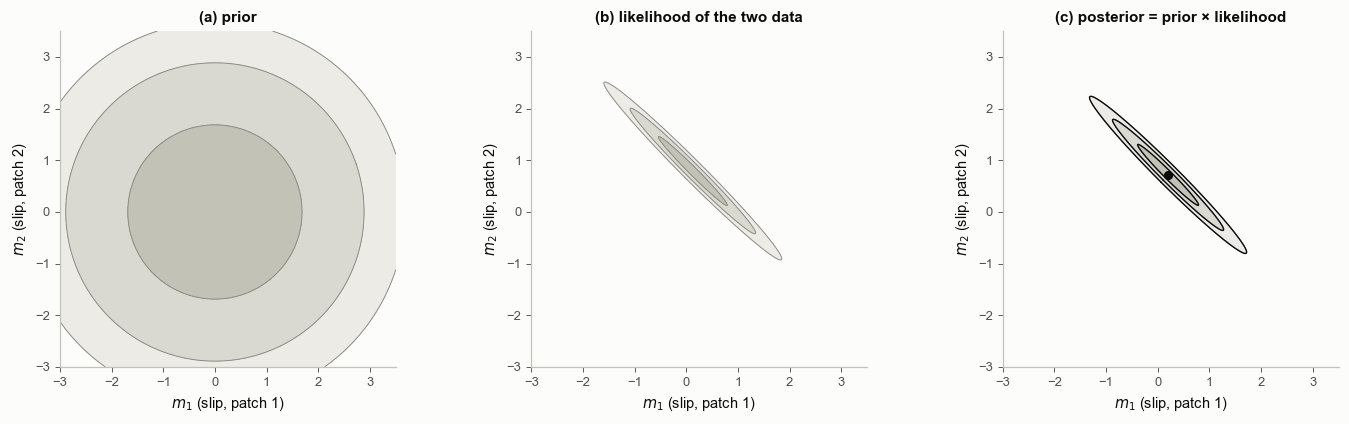

posterior mean [0.199 0.718]  posterior sd [0.501 0.501]  correlation -0.983
prior sd [1.5 1.5]


In [4]:
cor = P.correlated()
Gc, yc, sc = cor.G, cor.y, cor.sigma
m0c, Cmc = cor.m0, cor.P
mbar_c, Cpost_c = cor.exact
X, Y = np.meshgrid(np.linspace(-3, 3.5, 400), np.linspace(-3, 3.5, 400))
pts = np.stack([X, Y], -1)
lp_prior = -0.5 * np.einsum("...i,ij,...j->...", pts - m0c, np.linalg.inv(Cmc), pts - m0c)
pred = pts @ Gc.T
lp_lik = -0.5 * np.sum(((yc - pred) / sc) ** 2, axis=-1)
panels = [("(a) prior", lp_prior), ("(b) likelihood of the two data", lp_lik), ("(c) posterior = prior × likelihood", lp_prior + lp_lik)]
fig, axs = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (title, lp) in zip(axs, panels):
    Pm = np.exp(lp - lp.max())
    lev = sorted(set(P.hdr_levels(Pm).values()))
    ax.contourf(X, Y, Pm, levels=lev + [1.01], colors=["#ecebe6", "#d9d8d1", "#c3c2b7"])
    ax.contour(X, Y, Pm, levels=lev, colors=S.MUTED, linewidths=0.6)
    ax.set_title(title, fontsize=10); ax.set_aspect("equal")
    ax.set_xlabel("$m_1$ (slip, patch 1)"); ax.set_ylabel("$m_2$ (slip, patch 2)")
for q in (0.5, 0.9, 0.99):
    BP.ellipse(axs[2], mbar_c, Cpost_c, nsig=np.sqrt(-2 * np.log(1 - q)), color=S.INK, lw=0.9)
axs[2].plot(*mbar_c, "o", color=S.INK, ms=5)
fig.tight_layout()
bk.savefig(fig, "2-08_prior_lik_post")
plt.show()
print("posterior mean", np.round(mbar_c, 3), " posterior sd", np.round(np.sqrt(np.diag(Cpost_c)), 3),
      " correlation", round(Cpost_c[0, 1] / np.sqrt(Cpost_c[0, 0] * Cpost_c[1, 1]), 3))
print("prior sd", np.round(np.sqrt(np.diag(Cmc)), 3))

**How to read it.** Grey regions hold 50, 90 and 99 % of each distribution. In (c) the black ellipses are the closed
form $N(\bar{\mathbf m}, \tilde{\mathbf C}_m)$ for the same probabilities; they lie on the grid computation exactly,
because nothing here is approximate. The posterior is narrower than the prior in every direction (standard
deviations printed above) and keeps the tilt of the likelihood.

**Common misreadings.**
* *"With a prior, the answer is biased toward the prior."* Only in the directions the data do not constrain. Across
  the ellipse the data dominate; along it the prior decides, as it must.

## 3. The MAP: the lowest point of misfit plus prior penalty

**In plain words.** Take minus the logarithm of the posterior. It becomes a sum of two penalties: how badly the
model misfits the data, and how far the model strays from the prior. The single most probable model, the MAP, is the
model with the smallest total penalty. That is a regularised least-squares problem, so a regularised inversion
*is* a Bayesian MAP with a particular prior (2.09 lists which regulariser corresponds to which prior).

**Precisely.**

$$-\ln p(\mathbf m \mid \mathbf d) = \underbrace{\tfrac12(\mathbf d-\mathbf G\mathbf m)^\top\mathbf C_d^{-1}(\mathbf d-\mathbf G\mathbf m)}_{\Phi_d:\ \text{misfit}}
+ \underbrace{\tfrac12(\mathbf m-\mathbf m_0)^\top\mathbf C_m^{-1}(\mathbf m-\mathbf m_0)}_{\Phi_m:\ \text{prior penalty}} + \text{const},$$

(arg min: the $\mathbf m$ that makes the sum smallest; setting its gradient to zero gives the linear system on the right)

$$\hat{\mathbf m} = \arg\min(\Phi_d + \Phi_m) \;\Longleftrightarrow\;
(\mathbf G^\top\mathbf C_d^{-1}\mathbf G + \mathbf C_m^{-1})\,\hat{\mathbf m} = \mathbf G^\top\mathbf C_d^{-1}\mathbf d + \mathbf C_m^{-1}\mathbf m_0 .$$

For a linear-Gaussian problem the MAP equals the posterior mean and the median. To make the picture clear we use the
flat-direction problem of notebook 2.02: one datum that sees only $m_1 + m_2$, so least squares alone has a whole line
of equally good answers (a null space, 2.07), and the prior has to choose.

**Worked example.** Datum $d$ = 1 (σ = 0.15) of $m_1 + m_2$; prior mean (0.8, −0.4), prior sd 1 for each patch.

In [5]:
G3 = np.array([[1.0, 1.0]]); d3 = np.array([1.0]); s3 = 0.15
m03 = np.array([0.8, -0.4]); Cm3 = np.eye(2)
A3 = G3.T @ G3 / s3 ** 2 + np.linalg.inv(Cm3)
b3 = G3.T @ d3 / s3 ** 2 + np.linalg.inv(Cm3) @ m03
print("normal-equation matrix  G^T Cd^-1 G + Cm^-1 =\n", np.round(A3, 3))
print("right-hand side        G^T Cd^-1 d + Cm^-1 m0 =", np.round(b3, 3))
m_map3 = np.linalg.solve(A3, b3)
print("MAP =", np.round(m_map3, 4), "  (it fits the datum: m1 + m2 =", round(m_map3.sum(), 4), ")")
ls_line_point = m03 + (d3[0] - m03.sum()) / 2 * np.array([1, 1])     # point of the LS line closest to the prior mean
print("point of the least-squares line m1 + m2 = 1 closest to the prior mean:", np.round(ls_line_point, 4))
# MAP path: scale the prior penalty by a weight w (w -> 0: data only; w -> infinity: prior only)
ws = np.logspace(-3, 3, 60)
path = np.array([np.linalg.solve(G3.T @ G3 / s3 ** 2 + w * np.linalg.inv(Cm3), G3.T @ d3 / s3 ** 2 + w * np.linalg.inv(Cm3) @ m03) for w in ws])

normal-equation matrix  G^T Cd^-1 G + Cm^-1 =
 [[45.444 44.444]
 [44.444 45.444]]
right-hand side        G^T Cd^-1 d + Cm^-1 m0 = [45.244 44.044]
MAP = [ 1.0967 -0.1033]   (it fits the datum: m1 + m2 = 0.9933 )
point of the least-squares line m1 + m2 = 1 closest to the prior mean: [ 1.1 -0.1]


saved figures/2-08_map_objective.png


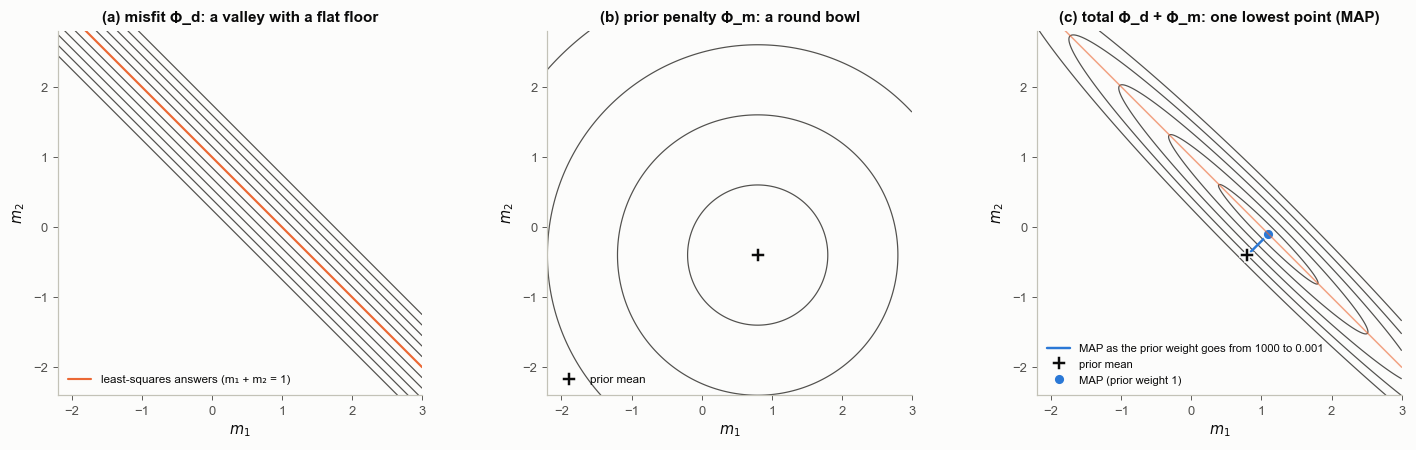

In [6]:
X3, Y3 = np.meshgrid(np.linspace(-2.2, 3.0, 400), np.linspace(-2.4, 2.8, 400))
pts3 = np.stack([X3, Y3], -1)
Phi_d = 0.5 * ((d3[0] - (X3 + Y3)) / s3) ** 2
Phi_m = 0.5 * np.einsum("...i,ij,...j->...", pts3 - m03, np.linalg.inv(Cm3), pts3 - m03)
fig, axs = plt.subplots(1, 3, figsize=(13.5, 4.1))
for ax, (title, F, lev) in zip(axs, [("(a) misfit Φ_d: a valley with a flat floor", Phi_d, [0.5, 2, 4.5, 8, 12.5]),
                                     ("(b) prior penalty Φ_m: a round bowl", Phi_m, [0.5, 2, 4.5, 8, 12.5]),
                                     ("(c) total Φ_d + Φ_m: one lowest point (MAP)", Phi_d + Phi_m, None)]):
    if lev is None:
        Fm = F.min()
        lev = Fm + np.array([0.5, 2, 4.5, 8, 12.5])
    cs = ax.contour(X3, Y3, F, levels=lev, colors=S.INK2, linewidths=0.8)
    ax.set_title(title, fontsize=10); ax.set_aspect("equal")
    ax.set_xlabel("$m_1$"); ax.set_ylabel("$m_2$")
axs[0].plot([-2.2, 3.0], [3.2, -2.0], color=S.ORANGE, lw=1.4, label="least-squares answers (m₁ + m₂ = 1)")
axs[0].legend(fontsize=7.6, loc="lower left")
axs[1].plot(*m03, "P", color=S.INK, ms=9, mec=S.SURFACE, label="prior mean")
axs[1].legend(fontsize=7.6, loc="lower left")
axs[2].plot(path[:, 0], path[:, 1], color=S.BLUE, lw=1.6, label="MAP as the prior weight goes from 1000 to 0.001")
axs[2].plot(*m03, "P", color=S.INK, ms=9, mec=S.SURFACE, label="prior mean")
axs[2].plot(*m_map3, "o", color=S.BLUE, ms=7, mec=S.SURFACE, label="MAP (prior weight 1)")
axs[2].plot([-2.2, 3.0], [3.2, -2.0], color=S.ORANGE, lw=1.0, alpha=0.6)
axs[2].legend(fontsize=7.4, loc="lower left")
for ax in axs:
    ax.set_xlim(-2.2, 3.0); ax.set_ylim(-2.4, 2.8)
fig.tight_layout()
bk.savefig(fig, "2-08_map_objective")
plt.show()

**How to read it.** (a) The misfit has a valley whose floor is the whole orange line: every point on it fits the
datum perfectly, so least squares cannot choose. (b) The prior penalty is a bowl around the prior mean. (c) Their
sum has a single lowest point, the MAP. As the prior weight shrinks, the MAP slides along the blue path to the point
of the least-squares line closest to the prior mean (printed above); as it grows, the MAP moves to the prior mean.
With weak priors this limit is the minimum-norm least-squares answer of 2.07 when the prior mean is zero: that
"neutral" answer was a prior all along.

**Common misreadings.**
* *"Regularisation is a numerical trick, separate from Bayes."* Minimising misfit + penalty is finding the MAP of a
  posterior whose prior is $\exp(-\text{penalty})$.
* *"The MAP is the answer."* It is one point. The posterior also says how far other models may be from it, which the
  MAP alone hides (section 5 shows a case where the MAP is not even typical).

## 4. Two equal formulas, and when to use which

**In plain words.** The same posterior can be computed in two ways. One works in the space of unknowns and inverts
a matrix as large as the number of unknowns; the other works in the space of data and inverts a matrix as large as
the number of data. The answers are identical; the cost is not. Use the smaller space.

**Precisely.** Model-space form:
$$\tilde{\mathbf C}_m = (\mathbf G^\top\mathbf C_d^{-1}\mathbf G + \mathbf C_m^{-1})^{-1},\qquad
\bar{\mathbf m} = \tilde{\mathbf C}_m(\mathbf G^\top\mathbf C_d^{-1}\mathbf d + \mathbf C_m^{-1}\mathbf m_0).$$
Data-space form, with the **Kalman gain** $\mathbf K = \mathbf C_m\mathbf G^\top(\mathbf G\mathbf C_m\mathbf G^\top + \mathbf C_d)^{-1}$:
$$\bar{\mathbf m} = \mathbf m_0 + \mathbf K(\mathbf d - \mathbf G\mathbf m_0),\qquad
\tilde{\mathbf C}_m = \mathbf C_m - \mathbf K\mathbf G\mathbf C_m .$$
The two are equal by the Woodbury matrix identity (an algebraic rule that rewrites the inverse of a sum of matrices).
The first inverts an $N_m \times N_m$ matrix, the second an $N_d \times N_d$ one. (2.04 shows the gain arising as the conditional mean of a joint Gaussian; 2.23 uses it in time.)

In [7]:
Nf = 30
z_edges = np.linspace(0.0, 30.0, Nf + 1)
zc = 0.5 * (z_edges[1:] + z_edges[:-1])
xs = np.array([1, 2, 3, 4, 6, 9, 13, 18, 25, 35, 50, 70.0])
xs = np.sort(np.r_[-xs, xs])


def patch_disp(x, z1, z2):
    return (np.arctan(z2 / x) - np.arctan(z1 / x)) / np.pi


Gf = 1000.0 * np.array([[patch_disp(x, z_edges[j], z_edges[j + 1]) for j in range(Nf)] for x in xs])
s_true = 2.0 * np.exp(-0.5 * ((zc - 12.0) / 4.0) ** 2)
sig_f = 3.0
d_f = Gf @ s_true + sig_f * np.random.default_rng(42).standard_normal(xs.size)


def model_space(G, d, cd, m0, Cm):
    """Posterior mean and covariance in model space; cd = diagonal of C_d (independent noise)."""
    Cpost = np.linalg.inv(G.T @ (G / cd[:, None]) + np.linalg.inv(Cm))   # invert an N_m x N_m matrix
    return Cpost @ (G.T @ (d / cd) + np.linalg.solve(Cm, m0)), Cpost


def data_space(G, d, cd, m0, Cm):
    """The same in data space with the Kalman gain; cd = diagonal of C_d."""
    S_ = G @ Cm @ G.T + np.diag(cd)                                     # an N_d x N_d matrix
    K = np.linalg.solve(S_, G @ Cm).T                                   # K = Cm G^T S^-1
    return m0 + K @ (d - G @ m0), Cm - K @ G @ Cm


Cd_f = np.full(xs.size, sig_f ** 2)
m0_f, Cm_f = np.zeros(Nf), np.eye(Nf)                      # iid prior, sd 1 m
ma, Ca = model_space(Gf, d_f, Cd_f, m0_f, Cm_f)
mb, Cb = data_space(Gf, d_f, Cd_f, m0_f, Cm_f)
print(f"fault toy (N_m = {Nf}, N_d = {xs.size}): max |mean difference| = {np.abs(ma - mb).max():.1e} m, max |covariance difference| = {np.abs(Ca - Cb).max():.1e} m^2")


def timed(f, *args, reps=3):
    best = np.inf
    for _ in range(reps):
        t0 = time.perf_counter(); f(*args); best = min(best, time.perf_counter() - t0)
    return best


rng4 = np.random.default_rng(4)
times = {}
for Nm, Nd in [(2000, 50), (50, 2000)]:
    zz = np.linspace(0, 100, Nm)
    Cm_big = np.exp(-np.abs(zz[:, None] - zz[None, :]) / 10.0) + 1e-6 * np.eye(Nm)     # dense prior covariance
    G_big = rng4.standard_normal((Nd, Nm)) / np.sqrt(Nm)
    Cd_big = np.full(Nd, 0.1 ** 2)
    d_big = G_big @ rng4.standard_normal(Nm) + 0.1 * rng4.standard_normal(Nd)
    m0_big = np.zeros(Nm)
    ta = timed(model_space, G_big, d_big, Cd_big, m0_big, Cm_big)
    tb = timed(data_space, G_big, d_big, Cd_big, m0_big, Cm_big)
    xa, _ = model_space(G_big, d_big, Cd_big, m0_big, Cm_big)
    xb, _ = data_space(G_big, d_big, Cd_big, m0_big, Cm_big)
    times[(Nm, Nd)] = (ta, tb)
    print(f"N_m = {Nm:4d}, N_d = {Nd:4d}: model space {1e3 * ta:8.2f} ms, data space {1e3 * tb:8.2f} ms  (same mean to {np.abs(xa - xb).max():.1e})")

fault toy (N_m = 30, N_d = 24): max |mean difference| = 1.6e-11 m, max |covariance difference| = 6.4e-13 m^2


N_m = 2000, N_d =   50: model space   252.66 ms, data space    48.35 ms  (same mean to 6.4e-13)
N_m =   50, N_d = 2000: model space     0.15 ms, data space    36.19 ms  (same mean to 3.5e-14)


saved figures/2-08_two_forms_cost.png


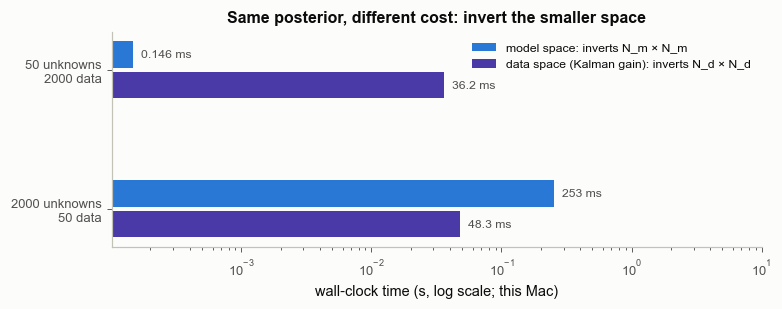

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 2.9))
labels, ypos = [], []
for i, ((Nm, Nd), (ta, tb)) in enumerate(times.items()):
    ax.barh(2 * i + 0.22, ta, height=0.38, color=S.BLUE, label="model space: inverts N_m × N_m" if i == 0 else None)
    ax.barh(2 * i - 0.22, tb, height=0.38, color=S.VIOLET, label="data space (Kalman gain): inverts N_d × N_d" if i == 0 else None)
    ax.text(ta * 1.15, 2 * i + 0.22, f"{1e3 * ta:.3g} ms", va="center", fontsize=8, color=S.INK2)
    ax.text(tb * 1.15, 2 * i - 0.22, f"{1e3 * tb:.3g} ms", va="center", fontsize=8, color=S.INK2)
    labels.append(f"{Nm} unknowns\n{Nd} data"); ypos.append(2 * i)
ax.set_yticks(ypos); ax.set_yticklabels(labels)
ax.set_xscale("log"); ax.set_xlabel("wall-clock time (s, log scale; this Mac)")
ax.set_title("Same posterior, different cost: invert the smaller space")
ax.legend(fontsize=8, loc="upper right")
ax.set_xlim(right=max(max(v) for v in times.values()) * 40)
fig.tight_layout()
bk.savefig(fig, "2-08_two_forms_cost")
plt.show()

**How to read it.** With many unknowns and few data, the data-space form is the cheap one; with few unknowns and
many data, the model-space form is. Both give the same mean to round-off (printed). Times are for this machine and
change with the hardware, but the ranking follows the matrix sizes.

**Common misreadings.**
* *"The Kalman-gain formula is only for filters."* It is the static Bayesian update written in data space; filters
  (2.23) apply it repeatedly.
* *"Both forms are equally stable."* With a nearly flat prior, $\mathbf C_m - \mathbf K\mathbf G\mathbf C_m$ can
  lose precision (notebook 2.33 meets this); the precision (model-space) form or the Joseph form (a rearrangement of
  the same update that stays symmetric and positive definite under round-off) is safer there.

**In practice.** The ETKF (ensemble transform Kalman filter) form of ensemble Kalman inversion does a data-space-style
update in the space of ensemble
members (a $J \times J$ matrix), which is why it stays affordable with thousands of unknowns (2.24).

## 5. MAP, mean and median are different when the posterior is not Gaussian

**In plain words.** Slip on a thrust (a fault where one block is pushed up over the other) cannot be negative. Suppose the prior says "positive, usually below a couple of
metres" and one noisy measurement comes out slightly negative. The single most probable value is then exactly zero
slip, right at the boundary. But the average of all plausible slips is clearly positive, because every plausible
value is zero or more. Which number you report depends on the question you ask.

**Precisely.** The mean minimises the expected squared error $\mathbb E(m - \hat m)^2$, and the median the expected
absolute error $\mathbb E|m - \hat m|$. The MAP is often said to minimise the expected "0-1 loss" (1 for a miss, 0
for a hit), but that is exact only for *discrete* parameters. For a continuous posterior every single value has
probability zero, so under an exact 0-1 loss every estimate scores the same. The MAP is instead the limit of the best
estimate under a loss that counts a hit within a tolerance ε, as ε shrinks to zero (for well-behaved densities). It
also has a property the mean lacks: it moves when the parameter is rewritten in other units, for example slip versus
log slip (2.11 and 2.32 show this). For a symmetric single-peaked posterior (any Gaussian) the three summaries
coincide; for a skewed or bounded one they do not.

**Worked example** (inputs: prior HalfNormal with scale 1 m, a Gaussian folded at zero so that only non-negative
values remain (2.11); datum $d$ = −0.2 m, σ = 0.5 m). The posterior is a
Gaussian truncated at zero; we compute it on a fine grid and compare with the truncated-normal formulas.

In [9]:
s_grid = np.linspace(0, 3, 30001)
post5 = st.halfnorm.pdf(s_grid, scale=1.0) * st.norm.pdf(-0.2, s_grid, 0.5)
post5 /= np.trapezoid(post5, s_grid)
cdf5 = np.cumsum(post5) * (s_grid[1] - s_grid[0])
cdf5 /= cdf5[-1]
map5 = s_grid[np.argmax(post5)]
mean5 = np.trapezoid(s_grid * post5, s_grid)
median5 = s_grid[np.searchsorted(cdf5, 0.5)]
lo5, hi5 = s_grid[np.searchsorted(cdf5, 0.025)], s_grid[np.searchsorted(cdf5, 0.975)]
prec5 = 1 / 1.0 ** 2 + 1 / 0.5 ** 2
mu5, sd5 = (-0.2 / 0.5 ** 2) / prec5, 1 / np.sqrt(prec5)                 # untruncated Gaussian
tn = st.truncnorm((0 - mu5) / sd5, np.inf, loc=mu5, scale=sd5)
print(f"untruncated combination: N({mu5:.3f}, {sd5:.3f}^2) -> truncated at 0")
print(f"MAP    (grid) {map5:.4f} m")
print(f"median (grid) {median5:.4f} m   formula {tn.median():.4f} m")
print(f"mean   (grid) {mean5:.4f} m   formula {tn.mean():.4f} m")
print(f"95 % interval {lo5:.3f} to {hi5:.3f} m;  probability that slip < 1 cm: {np.interp(0.01, s_grid, cdf5):.3f}")

untruncated combination: N(-0.160, 0.447^2) -> truncated at 0
MAP    (grid) 0.0000 m
median (grid) 0.2491 m   formula 0.2491 m
mean   (grid) 0.3045 m   formula 0.3045 m
95 % interval 0.011 to 0.898 m;  probability that slip < 1 cm: 0.023


saved figures/2-08_map_mean_median.png


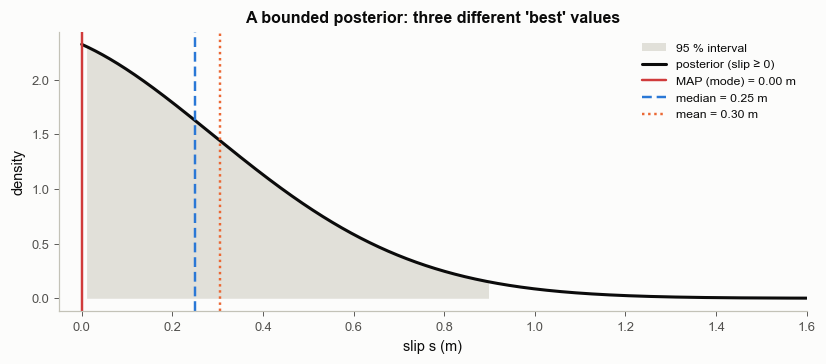

In [10]:
fig, ax = plt.subplots(figsize=(7.6, 3.4))
ax.fill_between(s_grid, post5, where=(s_grid >= lo5) & (s_grid <= hi5), color="#e1e0d9", lw=0, label="95 % interval")
ax.plot(s_grid, post5, color=S.INK, lw=2, label="posterior (slip ≥ 0)")
for x, name, c, ls in [(map5, "MAP (mode)", S.BAD, "-"), (median5, "median", S.BLUE, (0, (4, 2))), (mean5, "mean", S.ORANGE, (0, (1, 1.5)))]:
    ax.axvline(x, color=c, lw=1.6, ls=ls, label=f"{name} = {x:.2f} m")
ax.set_xlim(-0.05, 1.6)
ax.set_xlabel("slip s (m)"); ax.set_ylabel("density")
ax.set_title("A bounded posterior: three different 'best' values")
ax.legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-08_map_mean_median")
plt.show()

**How to read it.** The density is highest at zero, so the MAP is zero slip. Yet only a small probability lies
within 1 cm of zero (printed), and the median and mean are clearly positive. A slip map built from MAP values would
show "no slip" where the data only say "probably small".

**Common misreadings.**
* *"The MAP is the most likely value, so it is the best summary."* It answers the question "which value has the
  highest density?", and that answer depends on the coordinates chosen. For bounded or skewed posteriors report the
  median or mean together with an interval.

**In practice.** Any prior that bounds a parameter, through a truncation or a sigmoid transform (an S-shaped function
that maps any number into a bounded interval), produces posteriors
skewed like this one near the bound; notebook 2.33, section 6, shows positivity on the fault toy.

## 6. The Laplace approximation: a Gaussian fitted at the MAP

**In plain words.** For a nonlinear problem there is no closed form, but one can still find the MAP and measure how
sharply the posterior curves around it. Replacing the log posterior by a parabola with that curvature gives a
Gaussian approximation, the Laplace approximation. It is exact when the problem is linear and misleading when the
posterior bends.

**Precisely.** With $\hat{\mathbf m}$ the MAP and $\mathbf H = -\nabla^2 \ln p(\mathbf m\mid\mathbf d)\big|_{\hat{\mathbf m}}$
the **Hessian** (the matrix of second derivatives: the curvature of the log posterior in every pair of directions), $p(\mathbf m\mid\mathbf d) \approx N(\hat{\mathbf m}, \mathbf H^{-1})$. For the linear-Gaussian problem
$\mathbf H = \mathbf G^\top\mathbf C_d^{-1}\mathbf G + \mathbf C_m^{-1}$ exactly. (Notebook 2.02 met this ellipse; here
we look at why it fails.)

In [11]:
ban = P.location(kind="banana")
g_ban = P.grid(ban, n=500)
nlp = lambda z: -ban._logp_fn(jnp.asarray(z))
res6 = minimize(lambda z: float(nlp(z)), x0=np.array([0.3, -0.1]), jac=lambda z: np.asarray(jax.grad(nlp)(jnp.asarray(z))), method="BFGS")
H6 = np.asarray(jax.hessian(nlp)(jnp.asarray(res6.x)))
C_lap = np.linalg.inv(H6)
H_lin = np.asarray(jax.hessian(lambda z: -cor._logp_fn(z))(jnp.asarray(mbar_c)))
print(f"linear problem: max |Laplace covariance - exact posterior covariance| = {np.abs(np.linalg.inv(H_lin) - Cpost_c).max():.1e}")
print(f"banana: MAP {np.round(res6.x, 3)}, Laplace sd {np.round(np.sqrt(np.diag(C_lap)), 3)}")
print(f"        exact posterior mean {np.round(g_ban.mean, 3)}, exact sd {np.round(np.sqrt(np.diag(g_ban.cov)), 3)}")
md2 = lambda X_, Y_: np.einsum("...i,ij,...j->...", np.stack([X_ - res6.x[0], Y_ - res6.x[1]], -1), H6, np.stack([X_ - res6.x[0], Y_ - res6.x[1]], -1))
print(f"        exact posterior probability inside the Laplace 90 % ellipse: {g_ban.mass(lambda X_, Y_: md2(X_, Y_) < -2 * np.log(0.1)):.3f} (0.900 if it were right)")

linear problem: max |Laplace covariance - exact posterior covariance| = 9.4e-16
banana: MAP [0. 0.], Laplace sd [1.  0.1]
        exact posterior mean [-0.    -0.207], exact sd [0.956 0.309]
        exact posterior probability inside the Laplace 90 % ellipse: 0.627 (0.900 if it were right)


saved figures/2-08_laplace.png


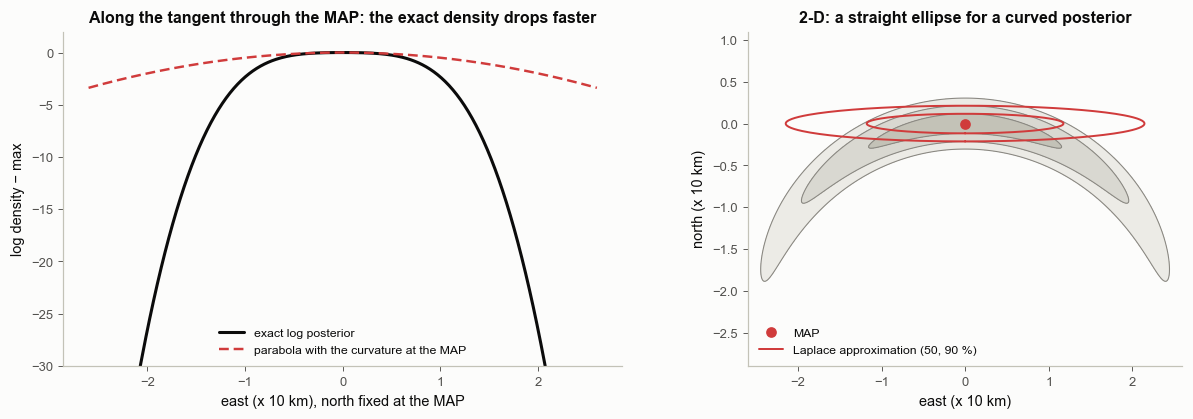

In [12]:
xs6 = np.linspace(-2.6, 2.6, 400)
lp_slice = -np.array([float(nlp(jnp.array([x, res6.x[1]]))) for x in xs6])
lp_quad = -float(nlp(jnp.asarray(res6.x))) - 0.5 * H6[0, 0] * (xs6 - res6.x[0]) ** 2
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.9))
ax = axs[0]
ax.plot(xs6, lp_slice - lp_slice.max(), color=S.INK, lw=2, label="exact log posterior")
ax.plot(xs6, lp_quad - lp_slice.max(), color=S.BAD, lw=1.6, ls=(0, (4, 2)), label="parabola with the curvature at the MAP")
ax.set_ylim(-30, 2)
ax.set_xlabel("east (x 10 km), north fixed at the MAP"); ax.set_ylabel("log density − max")
ax.set_title("Along the tangent through the MAP: the exact density drops faster")
ax.legend(fontsize=8, loc="lower center")
ax = axs[1]
BP.density(ax, g_ban)
for q in (0.5, 0.9):
    BP.ellipse(ax, res6.x, C_lap, nsig=np.sqrt(-2 * np.log(1 - q)), color=S.BAD, lw=1.3)
ax.plot(*res6.x, "o", color=S.BAD, ms=6, label="MAP")
ax.plot([], [], color=S.BAD, lw=1.3, label="Laplace approximation (50, 90 %)")
BP.frame(ax, ban, equal=True)
ax.set_title("2-D: a straight ellipse for a curved posterior")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
bk.savefig(fig, "2-08_laplace")
plt.show()

**How to read it.** Left: a slice along the east-west line through the MAP, which is the tangent to the arc. The
parabola and the exact log posterior agree at the peak, but away from it the exact density drops much faster: the arc
curves away from the tangent line, so points on the line soon misfit the datum. The Laplace Gaussian keeps going
straight along the tangent. Right: the result in 2-D. The red ellipses spread along the tangent, where the exact
posterior has little probability, and miss the arms that bend down; the printed probability inside the 90 % ellipse
is well below 0.90. For the linear problem the same calculation reproduces the exact covariance (printed).

**Common misreadings.**
* *"Error bars from the curvature at the best fit are the uncertainty."* Only for (nearly) linear problems;
  notebook 2.25 measures how nonlinear a problem must be before this fails.

## 7. How much did the data teach us, patch by patch?

**In plain words.** Compare each patch's uncertainty after the data with its uncertainty before. A ratio near zero
means the data pinned that patch down; a ratio near one means the data said nothing about it, and the answer there
is the prior. The same comparison can be counted in *bits*, the unit of information: halving the standard deviation
is one bit (2.27 develops this).

**Precisely.** Marginal ratio $\tilde\sigma_j/\sigma_{m,j}$ and marginal information gain
$\log_2(\sigma_{m,j}/\tilde\sigma_j)$ bits. The joint gain $\tfrac12\log_2(\lvert\mathbf C_m\rvert/\lvert\tilde{\mathbf C}_m\rvert)$
counts what was learned about all patches together (the determinant $\lvert\mathbf C\rvert$, 2.06, measures the
volume of the uncertainty ellipsoid). With an independent prior the joint gain is never smaller than the sum of the
marginal gains: the data also teach about combinations of patches that no single patch shows (in 2.27's language,
entropy is subadditive). With a correlated prior the sum can exceed the joint gain, because the same information is
counted again at every correlated neighbour.

In [13]:
def matern(z, ell, nu=1.0, amp=1.0):
    r = np.abs(z[:, None] - z[None, :])
    x = np.sqrt(2 * nu) * r / ell
    with np.errstate(invalid="ignore", divide="ignore"):
        C = amp ** 2 * 2 ** (1 - nu) / gamma(nu) * x ** nu * kv(nu, x)
    C[r == 0] = amp ** 2
    return C + 1e-9 * np.eye(z.size)


priors7 = {"iid Gaussian (sd 1 m)": np.eye(Nf), "Matérn (ℓ = 5 km, ν = 1, sd 1 m)": matern(zc, 5.0)}
info7 = {}
for name, Cm in priors7.items():
    mbar7, C7 = model_space(Gf, d_f, Cd_f, np.zeros(Nf), Cm)
    ratio = np.sqrt(np.diag(C7)) / np.sqrt(np.diag(Cm))
    joint = 0.5 * (np.linalg.slogdet(Cm)[1] - np.linalg.slogdet(C7)[1]) / np.log(2)
    info7[name] = (ratio, mbar7)
    print(f"{name:34s}: sd ratio from {ratio.min():.3f} (best patch) to {ratio.max():.3f};  "
          f"sum of marginal gains {np.sum(-np.log2(ratio)):.1f} bits, joint gain {joint:.1f} bits")

iid Gaussian (sd 1 m)             : sd ratio from 0.081 (best patch) to 0.968;  sum of marginal gains 7.8 bits, joint gain 23.8 bits
Matérn (ℓ = 5 km, ν = 1, sd 1 m)  : sd ratio from 0.039 (best patch) to 0.695;  sum of marginal gains 40.7 bits, joint gain 26.3 bits


saved figures/2-08_information_per_patch.png


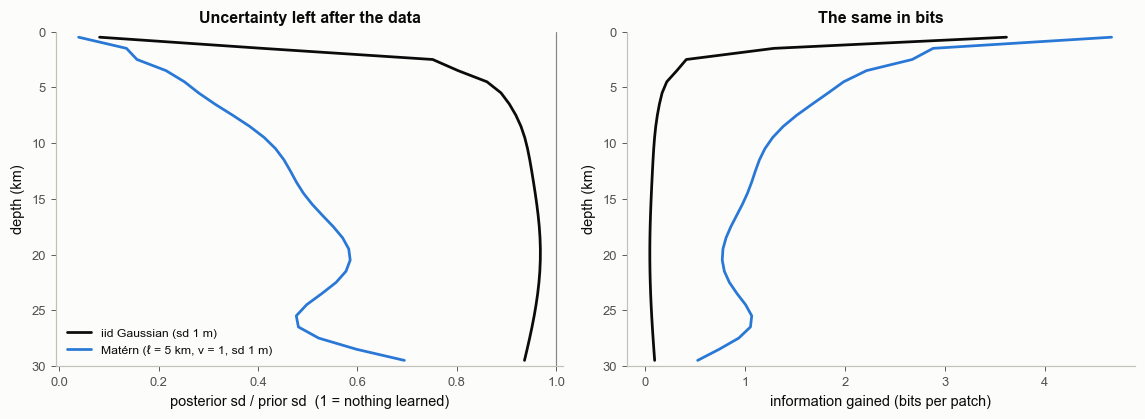

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.9))
for (name, (ratio, mbar7)), c in zip(info7.items(), [S.INK, S.BLUE]):
    axs[0].plot(ratio, zc, color=c, lw=1.8, label=name)
    axs[1].plot(-np.log2(ratio), zc, color=c, lw=1.8, label=name)
axs[0].axvline(1, color=S.MUTED, lw=0.8)
axs[0].set_xlabel("posterior sd / prior sd  (1 = nothing learned)"); axs[0].set_title("Uncertainty left after the data")
axs[1].set_xlabel("information gained (bits per patch)"); axs[1].set_title("The same in bits")
for ax in axs:
    ax.set_ylim(30, 0); ax.set_ylabel("depth (km)")
axs[0].legend(fontsize=8, loc="lower left")
fig.tight_layout()
bk.savefig(fig, "2-08_information_per_patch")
plt.show()

**How to read it.** Shallow patches lose most of their prior uncertainty; deep ones keep most of it, so their
posterior there is mostly the prior. The correlated (Matérn) prior, one in which neighbouring patches are correlated
over a set distance (2.09, 2.12), spreads what the data say about one patch to its neighbours, so individual patches
look better determined. The printed totals show both directions of the precise statement above: with the iid prior
(independent and identically distributed: every patch has the same prior and none is correlated) the joint gain is larger than the sum of the per-patch gains (the data
fix combinations such as the sum of neighbouring slips), with the Matérn prior the per-patch sum is larger (the same
information counted at each correlated neighbour). Judge what the data taught from the joint number, or from the
per-patch ratio read together with the prior.

**Common misreadings.**
* *"A small posterior sd at depth means the data constrain deep slip."* Compare it with the prior sd first. If the
  ratio is near 1 the number came from the prior.

**In practice.** Showing prior and posterior side by side (as notebook 2.33, section 8, does with the resolution
matrix) is the quickest way to tell readers which features of a slip model come from the data.

Next: [**2.09 · Regularisation and smoothing are priors**](2-09_regularisation_smoothing.ipynb).